In [2]:
import pandas as pd
from pathlib import Path

# Locate the project folder
current_path = Path.cwd()

if current_path.name == "notebooks":
    project_root = current_path.parent
else:
    project_root = current_path

# File locations
orders_path = project_root / "data" / "raw" / "olist_orders_dataset.csv"
reviews_path = project_root / "data" / "raw" / "olist_order_reviews_dataset.csv"

# Check that both files exist
print("Orders file exists:", orders_path.exists())
print("Reviews file exists:", reviews_path.exists())

# Load only the columns needed for this analysis
orders_df = pd.read_csv(
    orders_path,
    usecols=[
        "order_id",
        "order_status",
        "order_delivered_customer_date",
        "order_estimated_delivery_date"
    ]
)

reviews_df = pd.read_csv(
    reviews_path,
    usecols=["order_id", "review_score"]
)

# Convert delivery dates to proper datetime values
date_columns = [
    "order_delivered_customer_date",
    "order_estimated_delivery_date"
]

for col in date_columns:
    orders_df[col] = pd.to_datetime(orders_df[col], errors="coerce")

# Inspect the datasets
print("\nOrders shape:", orders_df.shape)
print("Reviews shape:", reviews_df.shape)

print("\nOrders data:")
display(orders_df.head())

print("\nReviews data:")
display(reviews_df.head())

print("\nMissing values in orders:")
print(orders_df.isna().sum())

print("\nMissing values in reviews:")
print(reviews_df.isna().sum())

Orders file exists: True
Reviews file exists: True

Orders shape: (99441, 4)
Reviews shape: (99224, 2)

Orders data:


,order_id,order_status,order_delivered_customer_date,order_estimated_delivery_date
0,e481f51cbdc54678b7cc49136f2d6af7,delivered,2017-10-10 21:25:13,2017-10-18
1,53cdb2fc8bc7dce0b6741e2150273451,delivered,2018-08-07 15:27:45,2018-08-13
2,47770eb9100c2d0c44946d9cf07ec65d,delivered,2018-08-17 18:06:29,2018-09-04
3,949d5b44dbf5de918fe9c16f97b45f8a,delivered,2017-12-02 00:28:42,2017-12-15
4,ad21c59c0840e6cb83a9ceb5573f8159,delivered,2018-02-16 18:17:02,2018-02-26



Reviews data:


,order_id,review_score
0,73fc7af87114b39712e6da79b0a377eb,4
1,a548910a1c6147796b98fdf73dbeba33,5
2,f9e4b658b201a9f2ecdecbb34bed034b,5
3,658677c97b385a9be170737859d3511b,5
4,8e6bfb81e283fa7e4f11123a3fb894f1,5



Missing values in orders:
order_id                            0
order_status                        0
order_delivered_customer_date    2965
order_estimated_delivery_date       0
dtype: int64

Missing values in reviews:
order_id        0
review_score    0
dtype: int64


In [1]:
import pandas as pd
from pathlib import Path

In [3]:
# 1. Keep delivered orders with valid delivery dates
valid_orders = orders_df.loc[
    (orders_df["order_status"] == "delivered")
    & orders_df["order_delivered_customer_date"].notna()
    & orders_df["order_estimated_delivery_date"].notna()
].copy()

# 2. Calculate days compared with the estimated delivery date
valid_orders["days_vs_estimated"] = (
    valid_orders["order_delivered_customer_date"].dt.normalize()
    - valid_orders["order_estimated_delivery_date"].dt.normalize()
).dt.days

# 3. Classify delivery performance
valid_orders["delivery_status"] = (
    valid_orders["days_vs_estimated"]
    .gt(0)
    .map({True: "Late", False: "On time or early"})
)

# 4. Calculate one average review score per order
reviews_by_order = (
    reviews_df
    .groupby("order_id", as_index=False)
    .agg(avg_review_score=("review_score", "mean"))
)

# 5. Merge orders with their review scores
analysis_df = valid_orders.merge(
    reviews_by_order,
    on="order_id",
    how="left",
    validate="one_to_one"
)

# 6. Flag low reviews (scores of 2 or lower)
analysis_df["is_low_review"] = (
    analysis_df["avg_review_score"].le(2)
    .where(analysis_df["avg_review_score"].notna())
)

print("Eligible delivered orders:", len(analysis_df))
print("Unique orders:", analysis_df["order_id"].nunique())
print("\nDelivery status counts:")
print(analysis_df["delivery_status"].value_counts())

print("\nPrepared dataset:")
display(analysis_df.head())

Eligible delivered orders: 96470
Unique orders: 96470

Delivery status counts:
delivery_status
On time or early    89936
Late                 6534
Name: count, dtype: int64

Prepared dataset:


,order_id,order_status,order_delivered_customer_date,order_estimated_delivery_date,days_vs_estimated,delivery_status,avg_review_score,is_low_review
0,e481f51cbdc54678b7cc49136f2d6af7,delivered,2017-10-10 21:25:13,2017-10-18,-8,On time or early,4.0,False
1,53cdb2fc8bc7dce0b6741e2150273451,delivered,2018-08-07 15:27:45,2018-08-13,-6,On time or early,4.0,False
2,47770eb9100c2d0c44946d9cf07ec65d,delivered,2018-08-17 18:06:29,2018-09-04,-18,On time or early,5.0,False
3,949d5b44dbf5de918fe9c16f97b45f8a,delivered,2017-12-02 00:28:42,2017-12-15,-13,On time or early,5.0,False
4,ad21c59c0840e6cb83a9ceb5573f8159,delivered,2018-02-16 18:17:02,2018-02-26,-10,On time or early,5.0,False


In [4]:
# Re-read the original date columns as text to check parsing
raw_dates = pd.read_csv(
    orders_path,
    usecols=[
        "order_id",
        "order_status",
        "order_delivered_customer_date",
        "order_estimated_delivery_date"
    ],
    dtype="string"
)

delivered_raw = raw_dates.loc[
    raw_dates["order_status"].eq("delivered")
].copy()

print("Raw delivered orders:", len(delivered_raw))

for col in [
    "order_delivered_customer_date",
    "order_estimated_delivery_date"
]:
    raw_value = delivered_raw[col].str.strip()

    parsed_value = pd.to_datetime(
        raw_value,
        errors="coerce"
    )

    parse_failures = (
        raw_value.notna()
        & raw_value.ne("")
        & parsed_value.isna()
    )

    print(f"\n{col}")
    print("Blank or missing:", (raw_value.isna() | raw_value.eq("")).sum())
    print("Nonblank values that failed parsing:", parse_failures.sum())

    if parse_failures.any():
        display(delivered_raw.loc[parse_failures, ["order_id", col]].head(10))

Raw delivered orders: 96478

order_delivered_customer_date
Blank or missing: 8
Nonblank values that failed parsing: 0

order_estimated_delivery_date
Blank or missing: 0
Nonblank values that failed parsing: 0


In [2]:
import pandas as pd
from scipy.stats import mannwhitneyu

# 1. Summarise delivery performance and customer reviews
summary = (
    analysis_df
    .groupby("delivery_status")
    .agg(
        Delivered_Orders=("order_id", "size"),
        Reviewed_Orders=("avg_review_score", "count"),
        Average_Review=("avg_review_score", "mean"),
        Median_Review=("avg_review_score", "median")
    )
    .round(2)
)

# 2. Calculate percentage of low reviews (scores <= 2)
low_review_pct = (
    analysis_df.groupby("delivery_status")["is_low_review"]
    .mean()
    .mul(100)
)

summary["Low_Review_Percentage"] = (
    summary.index.map(low_review_pct).round(2)
)

display(summary)

# 3. Separate the review scores for each delivery group
late_scores = analysis_df.loc[
    analysis_df["delivery_status"] == "Late",
    "avg_review_score"
].dropna()

ontime_scores = analysis_df.loc[
    analysis_df["delivery_status"] == "On time or early",
    "avg_review_score"
].dropna()

# 4. Test whether the review-score distributions differ
test_result = mannwhitneyu(
    late_scores,
    ontime_scores,
    alternative="two-sided"
)

print("Late orders with reviews:", len(late_scores))
print("On-time/early orders with reviews:", len(ontime_scores))
print("Mann-Whitney U statistic:", round(test_result.statistic, 2))
print("P-value:", test_result.pvalue)

NameError: name 'analysis_df' is not defined

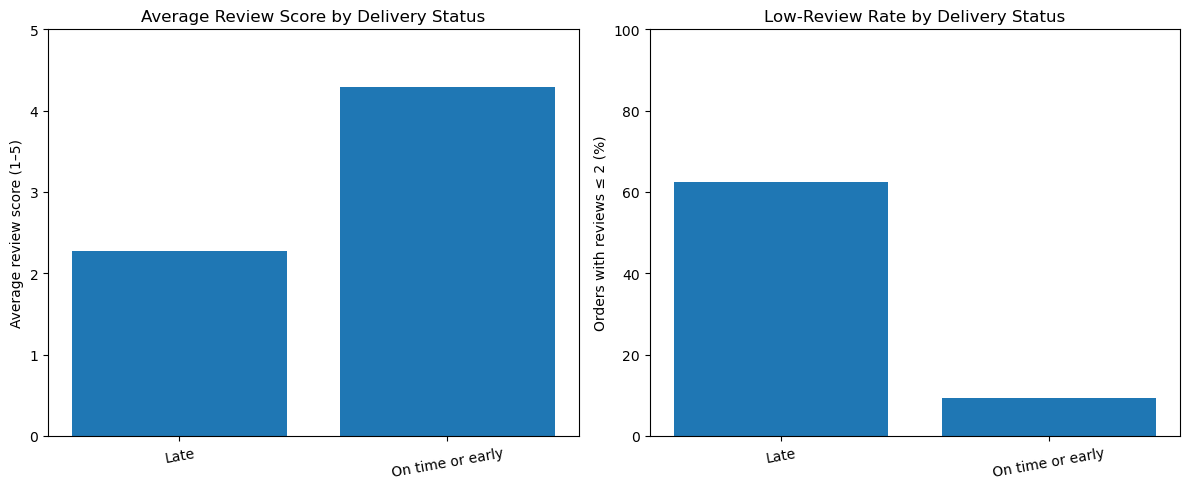

Chart saved to: /Users/khooshimangal/Desktop/ecommerce-SQL-analysis-git/reports/figures/06_delivery_review_comparison.png


In [6]:
import matplotlib.pyplot as plt
from pathlib import Path

# Keep the delivery groups in a logical order
plot_df = summary.reindex(["Late", "On time or early"])

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Chart 1: Average review score
axes[0].bar(plot_df.index, plot_df["Average_Review"])
axes[0].set_title("Average Review Score by Delivery Status")
axes[0].set_ylabel("Average review score (1–5)")
axes[0].set_ylim(0, 5)

# Chart 2: Percentage of low reviews
axes[1].bar(
    plot_df.index,
    plot_df["Low_Review_Percentage"]
)
axes[1].set_title("Low-Review Rate by Delivery Status")
axes[1].set_ylabel("Orders with reviews ≤ 2 (%)")
axes[1].set_ylim(0, 100)

for ax in axes:
    ax.tick_params(axis="x", rotation=10)

plt.tight_layout()

# Save inside the existing Git-connected project
figures_dir = project_root / "reports" / "figures"
figures_dir.mkdir(parents=True, exist_ok=True)

chart_path = figures_dir / "06_delivery_review_comparison.png"
fig.savefig(chart_path, dpi=200, bbox_inches="tight")

plt.show()

print("Chart saved to:", chart_path)

In [8]:
missing_delivery_orders = raw_dates.loc[
    raw_dates["order_status"].eq("delivered")
    & (
        raw_dates["order_delivered_customer_date"].isna()
        | raw_dates["order_delivered_customer_date"].str.strip().eq("")
    ),
    [
        "order_id",
        "order_delivered_customer_date",
        "order_estimated_delivery_date"
    ]
]

print("Delivered orders missing actual delivery dates:",
      len(missing_delivery_orders))

display(missing_delivery_orders)

Delivered orders missing actual delivery dates: 8


,order_id,order_delivered_customer_date,order_estimated_delivery_date
3002,2d1e2d5bf4dc7227b3bfebb81328c15f,<NA>,2017-12-18 00:00:00
20618,f5dd62b788049ad9fc0526e3ad11a097,<NA>,2018-07-16 00:00:00
43834,2ebdfc4f15f23b91474edf87475f108e,<NA>,2018-07-30 00:00:00
79263,e69f75a717d64fc5ecdfae42b2e8e086,<NA>,2018-07-30 00:00:00
82868,0d3268bad9b086af767785e3f0fc0133,<NA>,2018-07-24 00:00:00
92643,2d858f451373b04fb5c984a1cc2defaf,<NA>,2017-06-23 00:00:00
97647,ab7c89dc1bf4a1ead9d6ec1ec8968a84,<NA>,2018-06-26 00:00:00
98038,20edc82cf5400ce95e1afacc25798b31,<NA>,2018-07-19 00:00:00


In [2]:
import pandas as pd
from pathlib import Path

current_path = Path.cwd()

project_root = (
    current_path.parent
    if current_path.name == "notebooks"
    else current_path
)

reviews_path = (
    project_root / "data" / "raw" / "olist_order_reviews_dataset.csv"
)

print("Pandas loaded:", pd.__version__)
print("Reviews file exists:", reviews_path.exists())

Pandas loaded: 2.3.3
Reviews file exists: True


In [4]:
# Load the complete review data for comparison
reviews_check = pd.read_csv(
    reviews_path,
    usecols=["review_id", "order_id", "review_score"]
)

print("CSV total rows:", len(reviews_check))
print("Unique review IDs:", reviews_check["review_id"].nunique())
print("Unique orders:", reviews_check["order_id"].nunique())

print("\nDuplicate review IDs:",
      reviews_check["review_id"].duplicated().sum())

print("Duplicate complete rows:",
      reviews_check.duplicated().sum())

print("\nMissing values:")
print(reviews_check.isna().sum())

CSV total rows: 99224
Unique review IDs: 98410
Unique orders: 98673

Duplicate review IDs: 814
Duplicate complete rows: 0

Missing values:
review_id       0
order_id        0
review_score    0
dtype: int64



### Data Quality and Methodology

- The original review CSV contains 99,224 records, while the MySQL review table contains 99,172 records.
- The 52-record difference was identified during cross-validation.
- The Python analysis uses the original CSV as its source of truth.
- Eight delivered orders had missing actual delivery dates and were excluded.
- Reviews were aggregated to one average review score per order before merging.
- No completely duplicated review rows were found in the original CSV.
- The Mann–Whitney U test was used to compare review-score distributions between delivery groups.
- Results demonstrate an association, not proof of causation.
